In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ( accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report,
roc_curve, roc_auc_score)

In [48]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)
print("Features:")
print(X.head())
print("\nDataset Shape:")
print(X.shape)
print("\nFeature Names:")
print(data.feature_names)
print("\nTarget Classes:")
print(data.target_names)
print("\nClass Distribution:")
print(y.value_counts())
print("\nMissing Values:")
print(X.isnull().sum())

Features:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0 

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)
lr = LogisticRegression( max_iter=10000, C=1)
lr.fit(X_train_scaled, y_train)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

knn = KNeighborsClassifier( n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [51]:
def evaluate_model(model, X_test, y_test, name):
    prediction = model.predict(X_test)
    print("Accuracy:",accuracy_score(y_test, prediction))
    print("Precision:", precision_score(y_test, prediction, zero_division=0))
    print("Recall:",recall_score(y_test, prediction))
    print("F1 Score:", f1_score(y_test, prediction))
    print("\nClassification Report:")
    print(classification_report( y_test, prediction, zero_division=0))
    cm = confusion_matrix(y_test, prediction)
    ConfusionMatrixDisplay( confusion_matrix=cm ).plot()
    plt.title(name)
    plt.show()


Logistic Regression
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



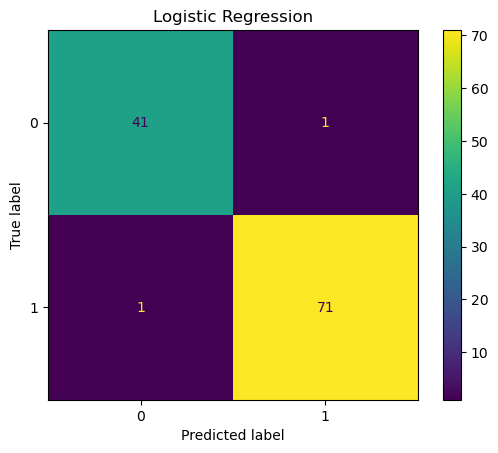

In [52]:
evaluate_model(lr, X_test_scaled,y_test,"Logistic Regression")


Decision Tree
Accuracy: 0.9122807017543859
Precision: 0.9558823529411765
Recall: 0.9027777777777778
F1 Score: 0.9285714285714286

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        42
           1       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



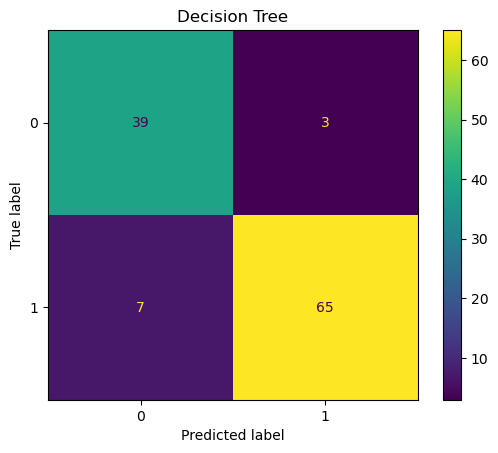

In [53]:
evaluate_model( dt, X_test, y_test, "Decision Tree")


KNN
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



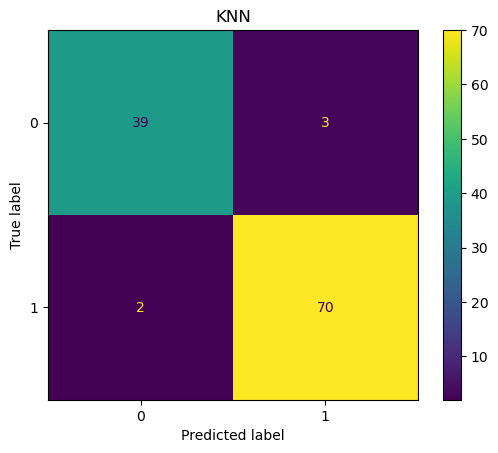

In [54]:
evaluate_model(knn,X_test_scaled,y_test,"KNN")

In [55]:
depth_values = [2,3,4,5,6,8,10,None]

for depth in depth_values:

    model = DecisionTreeClassifier(max_depth=depth,random_state=42)
    model.fit(X_train,y_train)
    prediction = model.predict(X_test)
    print("max_depth:", depth,"Accuracy:",accuracy_score(y_test,prediction) )

max_depth: 2 Accuracy: 0.8947368421052632
max_depth: 3 Accuracy: 0.9385964912280702
max_depth: 4 Accuracy: 0.9385964912280702
max_depth: 5 Accuracy: 0.9210526315789473
max_depth: 6 Accuracy: 0.9122807017543859
max_depth: 8 Accuracy: 0.9122807017543859
max_depth: 10 Accuracy: 0.9122807017543859
max_depth: None Accuracy: 0.9122807017543859


In [56]:
dt_best = DecisionTreeClassifier( max_depth=4,random_state=42)
dt_best.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [57]:
neighbors = [3,5,7,9,11,15]

for k in neighbors:

    model = KNeighborsClassifier(n_neighbors=k)
    model.fit( X_train_scaled, y_train )
    prediction=model.predict(X_test_scaled)
    print("n_neighbors:",k, "Accuracy:",accuracy_score(y_test,prediction))

n_neighbors: 3 Accuracy: 0.9824561403508771
n_neighbors: 5 Accuracy: 0.956140350877193
n_neighbors: 7 Accuracy: 0.9736842105263158
n_neighbors: 9 Accuracy: 0.9736842105263158
n_neighbors: 11 Accuracy: 0.9736842105263158
n_neighbors: 15 Accuracy: 0.9736842105263158


In [58]:
knn_best = KNeighborsClassifier(n_neighbors=5)
knn_best.fit( X_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [59]:
C_values=[0.01,0.1,1,10,100]

for c in C_values:
    model = LogisticRegression(C=c, max_iter=10000 )
    model.fit(X_train_scaled,y_train)
    prediction=model.predict(X_test_scaled)
    print("C:", c,"Accuracy:",accuracy_score(y_test,prediction))

C: 0.01 Accuracy: 0.9473684210526315
C: 0.1 Accuracy: 0.9736842105263158
C: 1 Accuracy: 0.9824561403508771
C: 10 Accuracy: 0.9649122807017544
C: 100 Accuracy: 0.9473684210526315


In [60]:
lr_best = LogisticRegression( C=100,max_iter=10000)
lr_best.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


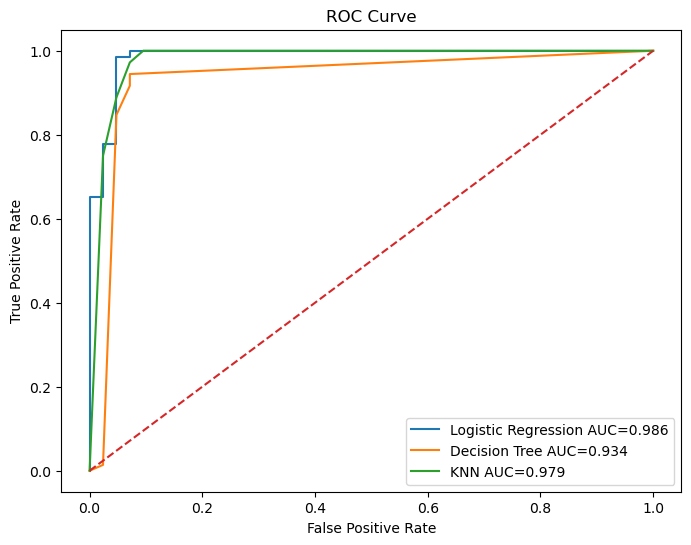

In [61]:
models = {"Logistic Regression": lr_best,"Decision Tree": dt_best,"KNN": knn_best}
plt.figure(figsize=(8,6))

for name,model in models.items():
    if name=="Decision Tree":
        X_eval=X_test
    else:
        X_eval=X_test_scaled
    probability = model.predict_proba(X_eval)[:,1]
    fpr,tpr,threshold = roc_curve( y_test, probability)
    auc = roc_auc_score(y_test,probability)
    plt.plot( fpr,tpr,label=f"{name} AUC={auc:.3f}")

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [62]:
probability = lr_best.predict_proba(X_test_scaled)[:,1]
thresholds=[0.3,0.5,0.7]

for threshold in thresholds:
    prediction = (probability >= threshold).astype(int)
    print("\nThreshold:",threshold)
    print("Accuracy:",accuracy_score(y_test,prediction))
    print("Precision:",precision_score( y_test,prediction))
    print("Recall:",recall_score(y_test,prediction))
    print("F1:",f1_score( y_test,prediction))


Threshold: 0.3
Accuracy: 0.9736842105263158
Precision: 0.9726027397260274
Recall: 0.9861111111111112
F1: 0.9793103448275862

Threshold: 0.5
Accuracy: 0.9473684210526315
Precision: 0.9714285714285714
Recall: 0.9444444444444444
F1: 0.9577464788732394

Threshold: 0.7
Accuracy: 0.9298245614035088
Precision: 0.9705882352941176
Recall: 0.9166666666666666
F1: 0.9428571428571428


In [63]:
for name,model in models.items():

    if name=="Decision Tree":
        train_X=X_train
        test_X=X_test
    else:
        train_X=X_train_scaled
        test_X=X_test_scaled
    train_accuracy = accuracy_score( y_train, model.predict(train_X))
    test_accuracy = accuracy_score( y_test, model.predict(test_X))
    print("\n",name)
    print("Training Accuracy:",train_accuracy)
    print("Testing Accuracy:", test_accuracy)


 Logistic Regression
Training Accuracy: 0.9934065934065934
Testing Accuracy: 0.9473684210526315

 Decision Tree
Training Accuracy: 0.9868131868131869
Testing Accuracy: 0.9385964912280702

 KNN
Training Accuracy: 0.9736263736263736
Testing Accuracy: 0.956140350877193
